# MIRI SMDS spectral fitting

Same joint BAGPIPES + TLUSTY supermassive dark star (SMDS) fit as `organized_notebooks/01_spectral_fitting.ipynb`, applied to the prepped MIRI 1D spectra in `data/miri_spectra_csv/`.

Catalog: `data/miri_dja_spectra_ready.csv` (DJA NIRSpec grade-3 z>9 matches with downloaded MIRI `*_x1d`).

## MIRI-specific changes

- Model wavelength windows extend to ~30 µm (original NIRSpec example stopped near 5.3 µm).
- Resolving power defaults to MIRI LRS (`R ~ 100`) or MRS (`R ~ 1500`).
- Redshifts and CSV paths come from the ready catalog; Lyα sits blueward of MIRI.
- Fit uses the MIRI LRS reliable window `[5, 12]` µm (drop noisy band edges) and inverse-variance weights from `Flux_Error`.
- Soft walls on SMDS `logM` \(\in [5, 8.5]\) and galaxy `logM` \(\in [6, 11]\).

## Files expected

- `data/miri_dja_spectra_ready.csv` and CSVs with columns `Wavelength` (µm), ` Flux` (f_λ × 1e21), and `Flux_Error`.
- TLUSTY templates in `tlusty_templates/` (`TEMPLATE_GRIDS`).

Set `SOURCE_ROW = i` to fit catalog row `i`.


In [1]:
import os
os.environ["PATH"] = "/data/apps/extern/spack_on/gcc/9.3.0/texlive/20220321-oikenzl6gekq5lsohdm6jnnuj276s2ba/bin/x86_64-linux:" + os.environ.get("PATH", "")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad  # numerical integral for luminosity distance
from scipy.interpolate import interp1d  # connect discrete template and model grids
from scipy.ndimage import gaussian_filter1d  # blur the galaxy spectrum to the instrument resolution
from scipy.optimize import minimize  # Nelder-Mead mean-squared-error fits

# Observed CSVs store f_lambda already multiplied by 1e21, so the numbers are not tiny.
# The galaxy model is in real physical units, so multiply it by this before comparing it to the data.
GALAXY_UNIT_SCALE = 1e21
# The dark-star function already returns flux in those same 1e21 units, so its extra scale is 1.
SMDS_UNIT_SCALE = 1.0

# Two slightly different cosmologies, kept because the original drafts disagreed.
# Distance depends on the expansion rate H0 (km/s/Mpc) and the matter density Om.
# Dark-star flux uses H0 = 72, Om = 0.27.
COSMO_SMDS = dict(H0=72.0, Om=0.27)
# Galaxy flux uses H0 = 70, Om = 0.3 (the BAGPIPES draft).
COSMO_GALAXY = dict(H0=70.0, Om=0.3)

C_CGS = 2.99792458e10  # speed of light, cm/s

# Soft walls on log10(M/Msun) for SMDS and galaxy components in the joint fit
LOGM_DS_MIN, LOGM_DS_MAX = 5.0, 8.5
LOGM_GAL_MIN, LOGM_GAL_MAX = 6.0, 11.0
# MIRI LRS reliable window; drop noisy band edges before fitting
LAM_FIT_MIN_UM, LAM_FIT_MAX_UM = 5.0, 12.0

# paths
DATA_DIR = Path("data")
SPEC_DIR = DATA_DIR / "miri_spectra_csv"
CATALOG_PATH = DATA_DIR / "miri_dja_spectra_ready.csv"
TEMPLATE_DIR = Path("tlusty_templates")

# Catalog row to fit (0-based index in miri_dja_spectra_ready.csv).
SOURCE_ROW = 1

plt.rcParams.update({"mathtext.fontset": "stix", "axes.grid": False})


## 1. Distance and unit conversion functions


In [2]:
def luminosity_distance_cm(z, H0=70.0, Om=0.3):
    """Flat LCDM luminosity distance in cm. z=0 returns 0.
    """
    z = float(z)
    if z <= 0:
        return 0.0

    H0_si = H0 * 1e5 / 3.085677581e24  # km/s/Mpc -> 1/s
    Ol = 1.0 - Om  # dark energy density

    def inv_e(zp):
        # 1/E(z): how the expansion rate at redshift zp compares with today
        return 1.0 / np.sqrt(Om * (1.0 + zp) ** 3 + Ol)

    # Comoving distance is the integral of 1/E from 0 to z.
    chi = quad(inv_e, 0.0, z, epsabs=0, epsrel=1e-6)[0]
    # Luminosity distance is the comoving distance times (1+z).
    return (1.0 + z) * (C_CGS / H0_si) * chi


def nJy_to_flambda_1e21(nJy, wavelength_um):
    """nJy -> f_lambda [erg/s/cm^2/A] * 1e21, at wavelength in microns.

    Flux can be quoted per frequency (nJy) or per wavelength (erg/s/cm^2/A).
    The extra 1e21 matches the CSV convention of the pipeline.
    """
    jy = np.asarray(nJy, float) * 1e-9  # nanojansky -> jansky
    f_nu = jy * 1e-23  # jansky -> erg/s/cm^2/Hz
    lam_cm = np.asarray(wavelength_um, float) * 1e-4  # microns -> cm
    f_per_cm = f_nu * (C_CGS / lam_cm ** 2)  # f_lambda = f_nu * c / lambda^2
    f_per_A = f_per_cm * 1e-8  # per cm of wavelength -> per angstrom (1 A = 1e-8 cm)
    return f_per_A * 1e21  # match the CSV files, which store flux times 1e21


def flambda_1e21_to_nJy(f_1e21, wavelength_um):
    """Inverse of the above function."""
    f_per_A = np.asarray(f_1e21, float) * 1e-21  # undo the CSV scale factor
    f_per_cm = f_per_A * 1e8  # per angstrom -> per cm
    lam_cm = np.asarray(wavelength_um, float) * 1e-4  # microns -> cm
    f_nu = f_per_cm * (lam_cm ** 2) / C_CGS  # per wavelength -> per frequency
    return f_nu / 1e-23 * 1e9  # erg/s/cm^2/Hz -> jansky -> nanojansky


## 2. TLUSTY templates

`T3` is the grid used by the later joint fit. `AC` is the earlier grid, including the `ACM*` files above `10^6 Msun`, used for the JADES-GS-z11 example and the morphology SEDs.


In [3]:
def fortran_float(value):
    # Fortran writes 1.23D+04 for 1.23e4. Python's float() only understands E.
    return float(str(value).strip().replace("D", "E").replace("d", "e"))


def load_tlusty(path):
    """Return frequency [Hz] and TLUSTY surface flux columns."""
    # Whitespace-separated file with no header.
    # Column 0 is frequency in Hz. Column 1 is the flux at the star's surface.
    raw = pd.read_csv(path, header=None, sep=r"\s+", engine="python")
    freq = np.array([fortran_float(x) for x in raw.iloc[:, 0]])
    flux = np.array([fortran_float(x) for x in raw.iloc[:, 1]])
    return freq, flux


# Precomputed atmospheres at a few fixed masses. Masses are in units of 1e5 solar masses.
# T3 is the grid used by the joint fit. AC is the older grid, including the ACM* files above 1e6 Msun.
TEMPLATE_GRIDS = {
    "T3": {
        "mass_1e5": np.array([1, 2, 3, 4, 5, 6, 7, 10, 20, 30, 40, 50, 60, 70, 90], float),
        "files": [
            "T3M1_0e5.13", "T3M2_0e5.13", "T3M3_0e5.13", "T3M4_0e5.13",
            "T3M5_0e5.13", "T3M6_0e5.13", "T3M7_0e5.13", "T3M1_0e6.13",
            "T3M2_0e6.13", "T3M3_0e6.13", "T3M4_0e6.13", "T3M5_0e6.13",
            "T3M6_0e6.13", "T3M7_0e6.13", "T3M9_0e6.13",
        ],
    },
    "AC": {
        "mass_1e5": np.array(
            [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20, 30, 40, 50, 60, 70, 80, 90], float
        ),
        "files": [
            "T3M1_0e5.13", "T3M2_0e5.13", "T3M3_0e5.13", "T3M4_0e5.13",
            "T3M5_0e5.13", "T3M6_0e5.13", "T3M7_0e5.13", "T3M8_0e5.13",
            "T3M9_0e5.13", "T3M1_0e6.13", "ACM2_00e+06.13", "ACM3_00e+06.13",
            "ACM4_00e+06.13", "ACM5_00e+06.13", "ACM6_00e+06.13", "ACM7_00e+06.13",
            "ACM8_00e+06.13", "ACM9_00e+06.13",
        ],
    },
}
TEMPLATE_SET = "T3"  # which grid nearest_template uses when the caller does not name one

# Three reference stars. Straight lines in log(mass) connect their radius, surface gravity, and temperature.
# Masses between the anchors are interpolated. Masses outside them are extrapolated.
_M_ANCHOR = np.array([1e5, 1e6, 1e7])
_LOGM_ANCHOR = np.log10(_M_ANCHOR)
_LOGR_ANCHOR = np.log10(np.array([5.83e14, 9.12e14, 1.45e15]))  # photospheric radius, cm
_LOGG_ANCHOR = np.array([1.591, 2.202, 2.8])  # log10 of surface gravity
_LOGT_ANCHOR = np.log10(np.array([14000.0, 19000.0, 27000.0]))  # effective temperature, K

_interp_logR = interp1d(_LOGM_ANCHOR, _LOGR_ANCHOR, kind="linear", fill_value="extrapolate")
_interp_logg = interp1d(_LOGM_ANCHOR, _LOGG_ANCHOR, kind="linear", fill_value="extrapolate")
_interp_logT = interp1d(_LOGM_ANCHOR, _LOGT_ANCHOR, kind="linear", fill_value="extrapolate")


def radius_cm(mass_msun):
    """Photospheric radius [cm] from the three-point logM-logR relation."""
    return float(10.0 ** _interp_logR(np.log10(mass_msun)))


def log_g(mass_msun):
    # Surface gravity
    # Returned with the spectrum for reference; the fit does not use it
    return float(_interp_logg(np.log10(mass_msun)))


def teff(mass_msun):
    # Effective temperature in kelvin, from the three anchor points
    return float(10.0 ** _interp_logT(np.log10(mass_msun)))


def teff_powerlaw(mass_msun):
    # Alternate fit: log10 T = 0.1326255 log10(M/Msun) + 3.483
    # Kept only for comparison; the actual pipeline uses teff()
    return 10.0 ** (0.1326255 * np.log10(mass_msun) + 3.483)


def radius_cm_powerlaw(mass_msun):
    # Alternate fit: log10(R/AU) = 0.194265 log10(M/Msun) + 0.6197384
    # Kept only for comparison; the actual pipeline uses radius_cm()
    r_au = 10.0 ** (0.194265 * np.log10(mass_msun) + 0.6197384)
    return r_au * 1.496e13  # AU -> cm


## 3. Redshift a template onto an observed wavelength grid

Flux below Lyα (`0.1216 (1+z)` µm) is set to zero. `mu` rescales the nearest grid mass up to the requested mass.


In [4]:
def redshift_tlusty(freq, surf_flux, z, radius, mu=1.0, lam_max_um=30.0):
    """Observed wavelength [um] and f_lambda * 1e21.

    surf_flux is the TLUSTY surface-flux column. radius is in cm.
    mu is the dimensionless mass ratio M_requested / M_grid.
    """
    # Frequency -> wavelength, stretch by (1+z), and convert cm to microns
    lam_um = (C_CGS / freq) * (1.0 + z) * 1e4
    # Drop bad points and wavelengths longer than lam_max_um
    keep = np.isfinite(lam_um) & np.isfinite(surf_flux) & (lam_um > 0) & (lam_um <= lam_max_um)
    lam_um = lam_um[keep]
    surf = surf_flux[keep]
    # Sort wavelength in increasing order; required by later interpolation
    order = np.argsort(lam_um)
    lam_um = lam_um[order]
    surf = surf[order]
    # Drop duplicate wavelengths (zero gap after sorting).
    keep_unique = np.concatenate([[True], np.diff(lam_um) > 0])
    lam_um = lam_um[keep_unique]
    surf = surf[keep_unique]

    if z == 0:
        # No cosmological distance at z = 0. This is surface flux in nJy, not an observed flux.
        f_nJy = 4.0 * np.pi * surf * 1e32
    else:
        # Observed flux scales as 4 pi F (1+z) R^2 / D_L^2.
        # 1e32 turns erg/s/cm^2/Hz into nanojanskys (1e23 to get Jy, times 1e9 to get nJy).
        # Distance uses the dark-star cosmology, H0 = 72 and Om = 0.27.
        dl = luminosity_distance_cm(z, **COSMO_SMDS)
        f_nJy = 4.0 * np.pi * surf * (1.0 + z) * radius ** 2 / dl ** 2 * 1e32
    # Brighten or dim the nearest grid spectrum according to the requested mass
    f_nJy *= mu

    f_lam = nJy_to_flambda_1e21(f_nJy, lam_um)
    # Intergalactic hydrogen absorbs light shortward of Lyman-alpha, so set that flux to zero.
    lya = 0.1216 * (1.0 + z)  # microns
    f_lam = np.where(lam_um > lya, f_lam, 0.0)
    return lam_um, f_lam


def nearest_template(mass_msun, template_set=None):
    # Spectrum shape comes from the closest precomputed mass, not from a continuous model.
    grid = TEMPLATE_GRIDS[template_set or TEMPLATE_SET]
    mass_1e5 = mass_msun / 1e5  # grid masses are stored in units of 1e5 solar masses
    idx = int(np.argmin(np.abs(grid["mass_1e5"] - mass_1e5)))
    m_grid = float(grid["mass_1e5"][idx])
    return {
        "file": grid["files"][idx],
        "mass_1e5": m_grid,
        "mu": mass_1e5 / m_grid,  # e.g. 1.5e6 Msun on a 1e6 template gets mu = 1.5
        "path": TEMPLATE_DIR / grid["files"][idx],
    }


def spectrum_from_mass_z(mass_msun, z, obs_lambda_um, template_set=None,
                         min_um=1.0, max_um=30.0):
    """SMDS spectrum on obs_lambda_um [um], in the same 1e21 f_lambda units as the CSVs."""
    meta = nearest_template(mass_msun, template_set)
    freq, surf = load_tlusty(meta["path"])
    # Radius follows the requested mass, even though the spectrum shape is the nearest grid file.
    # Mass therefore enters twice: through the area R(M)^2, and through the extra factor mu.
    r_cm = radius_cm(mass_msun)
    lam, fl = redshift_tlusty(freq, surf, z, r_cm, mu=meta["mu"], lam_max_um=max_um)
    # Keep the near-infrared window, then interpolate onto the exact observed wavelengths.
    sel = (lam >= min_um) & (lam <= max_um)
    interp = interp1d(lam[sel], fl[sel], kind="linear", bounds_error=False, fill_value="extrapolate")
    meta.update({"R_cm": r_cm, "z": z, "mass_msun": float(mass_msun),
                 "logg": log_g(mass_msun), "Teff": teff(mass_msun)})
    return np.asarray(interp(np.asarray(obs_lambda_um, float)), float), meta


## 4. BAGPIPES galaxy spectrum

Rest-frame luminosity is generated at `redshift = 0` with BAGPIPES IGM disabled, then shifted by hand. Flux blueward of Lyα is zeroed when `apply_igm` is set. The Lyα core is capped at `lya_cap_factor` times the red-side continuum before the line-spread function is applied.

`model_flux_at_obs_lambda` returns BAGPIPES f_λ, not yet multiplied by `GALAXY_UNIT_SCALE`.


In [5]:
import bagpipes as pipes
import bagpipes.config as cfg

cfg.max_redshift = 30
# Turn off BAGPIPES's own intergalactic absorption. The redshift and the Lyman-alpha cut are applied by hand below.
for _flag in ("apply_igm", "use_igm", "include_igm"):
    if hasattr(cfg, _flag):
        setattr(cfg, _flag, False)


def constant_R_grid(lam_min_A, lam_max_A, R, pix_per_fwhm=3.0):
    # Resolving power R = lambda / Delta_lambda. Equal steps in log(lambda) keep R constant.
    # pix_per_fwhm = 3 means about three pixels across one resolution element.
    dln = (1.0 / R) / pix_per_fwhm
    grid = np.exp(np.arange(np.log(lam_min_A), np.log(lam_max_A) + dln, dln))
    return grid, dln


def galaxy_spectrum(
    z, logM, age, tau, Z, Av, logU, fesc,
    *,
    R=100.0,
    lam_min_A=3.0e4,
    lam_max_A=30.0e4,
    lya_cap_factor=3.0,
    lya_window_kms=600.0,
    apply_igm=True,
    veldisp_kms=80.0,
    eta_birthcloud=3.0,
):
    """Return (lam_A, f_lambda) on a constant-R observed grid. f_lambda is erg/s/cm^2/A.

    logM is log10 of the total stellar mass formed, in solar masses.
    age and tau are in Gyr. Star formation falls as exp(-t/tau).
    Z is the metal mass fraction. Av is V-band dust extinction (Calzetti curve).
    logU is how intensely young stars ionize the surrounding gas.
    fesc is the fraction of ionizing photons that escape instead of lighting up that gas.
    """
    # Rest-frame grid is a bit wider than the final observed window (pad = 5%),
    # so interpolation at the edges of the observed grid still has model points.
    dln = (1.0 / R) / 3.0
    pad = 1.05
    lam_rest = np.exp(np.arange(
        np.log((lam_min_A / (1.0 + z)) / pad),
        np.log((lam_max_A / (1.0 + z)) * pad) + dln,
        dln,
    ))
    lam_obs, dln_obs = constant_R_grid(lam_min_A, lam_max_A, R)

    # Ask BAGPIPES for a rest-frame spectrum at redshift 0. Redshift is applied below.
    # t_bc = 0.01 Gyr: stars younger than this sit in an extra dust cloud (eta).
    # veldisp broadens lines by the spread of stellar velocities, in km/s.
    comp = {
        "redshift": 0.0,
        "t_bc": 0.01,
        "veldisp": veldisp_kms,
        "exponential": {"age": age, "tau": tau, "massformed": logM, "metallicity": Z},
        "dust": {"type": "Calzetti", "Av": Av, "eta": eta_birthcloud},
        "nebular": {"logU": logU, "f_esc": fesc},
    }
    spec = np.asarray(pipes.model_galaxy(comp, spec_wavs=lam_rest).spectrum)
    lam_rf, L_rf = spec[:, 0], spec[:, 1]  # rest wavelength [A], luminosity per angstrom
    # Stretch the wavelength by (1+z). Divide luminosity by (1+z) because the same
    # energy is now spread over a wider wavelength interval.
    lam_of = lam_rf * (1.0 + z)
    L_of = L_rf / (1.0 + z)
    f_L = np.interp(lam_obs, lam_of, L_of, left=0.0, right=0.0)
    # Turn luminosity into flux at Earth. This distance uses H0 = 70, Om = 0.3.
    flux = f_L / (4.0 * np.pi * luminosity_distance_cm(z, **COSMO_GALAXY) ** 2)

    lya = 1215.67 * (1.0 + z)  # Lyman-alpha in the observed frame, angstroms
    if apply_igm:
        # Photons shortward of Lyman-alpha are absorbed by intergalactic hydrogen.
        flux = np.where(lam_obs >= lya, flux, 0.0)

    # Cap the Lyman-alpha spike before blurring. Within +/- lya_window_kms of line center,
    # flux cannot exceed lya_cap_factor times the continuum just redward of the line.
    c_kms = 2.99792458e5
    ln_lam = np.log(lam_obs)
    core = np.abs(ln_lam - np.log(lya)) <= (lya_window_kms / c_kms)
    if np.any(core):
        # Continuum window: 1000 to 5000 km/s redward of the line.
        shoulder = (
            (ln_lam >= np.log(lya) + 1000.0 / c_kms)
            & (ln_lam <= np.log(lya) + 5000.0 / c_kms)
        )
        if not np.any(shoulder):
            # Fallback if that velocity window is empty: 1% to 3% redward in wavelength.
            shoulder = (lam_obs >= 1.01 * lya) & (lam_obs <= 1.03 * lya)
        cont = np.median(flux[shoulder]) if np.any(shoulder) else np.median(flux)
        cont = max(float(cont), 1e-40)  # avoid a zero or negative cap
        flux = flux.copy()
        flux[core] = np.minimum(flux[core], lya_cap_factor * cont)

    # Blur to resolving power R. A Gaussian's full width is 2.355 times its standard deviation.
    # sigma_pix is that standard deviation measured in pixels of this log-wavelength grid.
    sigma_pix = ((1.0 / R) / 2.355) / dln_obs
    return lam_obs, gaussian_filter1d(flux, sigma_pix, mode="nearest")


def model_flux_at_obs_lambda(obs_lambda_um, params, **kwargs):
    # Evaluate the galaxy on its own grid, then interpolate onto the observed wavelengths.
    # Still in physical f_lambda. The fitter multiplies by GALAXY_UNIT_SCALE (1e21) later.
    # Outside the model grid the flux is 0.
    lam_A, flux = galaxy_spectrum(**params, **kwargs)
    order = np.argsort(lam_A)
    interp = interp1d(lam_A[order] / 1e4, flux[order], kind="linear",
                      bounds_error=False, fill_value=0.0)
    return interp(np.asarray(obs_lambda_um, float))


Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


## 5. Galaxy-only MSE fit

Positive parameters listed in `log_keys` (`age`, `tau`, `Z`) are optimized in log10. This function does not apply the Lyman-alpha cut itself; pass that cut in through `fit_mask`. Model flux is scaled by `GALAXY_UNIT_SCALE` inside the loss.


In [6]:
def _to_vec(params, keys, log_keys):
    # Pack a parameter dictionary into one array for the optimizer.
    # Keys in log_keys are stored as log10, so age, tau, and Z cannot go negative.
    return np.array([
        np.log10(params[k]) if k in log_keys else float(params[k]) for k in keys
    ])


def _from_vec(x, base, keys, log_keys):
    # Reverse of _to_vec. Start from the starting dictionary and overwrite the keys being fit.
    out = dict(base)
    for k, v in zip(keys, x):
        out[k] = float(10.0 ** v) if k in log_keys else float(v)
    return out


def fit_galaxy_mse(
    obs_lambda_um, obs_flux, start,
    fit_keys=("logM", "age", "tau", "Z", "Av", "logU", "fesc"),
    log_keys=("age", "tau", "Z"),
    fit_mask=None,
    nm_options=None,
    **spec_kwargs,
):
    # Galaxy-only fit. The Lyman-alpha wavelength cut is not applied here;
    # pass it in through fit_mask if you want to ignore the absorbed blue side.
    fit_keys = tuple(fit_keys)
    log_keys = set(log_keys)
    if fit_mask is None:
        lam, flux = obs_lambda_um, obs_flux
    else:
        # Loss uses only the wavelengths marked True in fit_mask.
        lam, flux = obs_lambda_um[fit_mask], obs_flux[fit_mask]

    def objective(x):
        p = _from_vec(x, start, fit_keys, log_keys)
        # Model is physical f_lambda; multiply by 1e21 to match the CSV units.
        model = model_flux_at_obs_lambda(lam, p, **spec_kwargs) * GALAXY_UNIT_SCALE
        resid = flux - model
        return float(np.mean(resid * resid))  # mean squared error

    # Nelder-Mead walks a simplex through parameter space and does not need derivatives.
    # Stop after 200 steps, or when a parameter moves by less than xatol, or the loss changes by less than fatol.
    res = minimize(
        objective, _to_vec(start, fit_keys, log_keys), method="Nelder-Mead",
        options={"maxiter": 200, "xatol": 1e-4, "fatol": 1e-6, **(nm_options or {})},
    )
    best = _from_vec(res.x, start, fit_keys, log_keys)
    # Best model on the full wavelength array, including pixels left out of the loss.
    full = model_flux_at_obs_lambda(obs_lambda_um, best, **spec_kwargs) * GALAXY_UNIT_SCALE
    return {"result": res, "best_params": best, "best_model_flux": full}


def mc_galaxy_fits(obs_lambda_um, obs_flux, start, fit_mask, n=30, rel_sigma=0.20,
                   seed=42, fit_keys=None, log_keys=None, **spec_kwargs):
    """Refit noisy copies of the spectrum. sigma = rel_sigma * |flux| at each pixel.

    A rough uncertainty check, not a full Bayesian posterior. The example cell does not call this.
    """
    rng = np.random.default_rng(seed)
    sigma = rel_sigma * np.abs(obs_flux)  # noise width is 20% of the flux at each pixel
    rows = []
    keys = fit_keys or ("logM", "age", "tau", "Z", "Av", "logU", "fesc")
    logs = log_keys or ("age", "tau", "Z")
    for i in range(n):
        noisy = rng.normal(obs_flux, sigma)  # one noisy copy of the observed spectrum
        out = fit_galaxy_mse(
            obs_lambda_um, noisy, start, fit_keys=keys, log_keys=logs,
            fit_mask=fit_mask, **spec_kwargs,
        )
        row = {"sample": i, "mse": float(out["result"].fun), "success": bool(out["result"].success)}
        row.update({k: out["best_params"][k] for k in out["best_params"]})
        rows.append(row)
    return pd.DataFrame(rows)  # scatter of these rows is a stand-in for the error bars


## 6. SMDS-only and joint fits

SMDS mass is fit as `log10(M/Msun)` with a quadratic wall outside `[5.0, 7.95]` (mass-only) or `[5.0, 8.5]` (joint). The joint fit also walls galaxy `logM` outside `[6.0, 11.0]`. When `obs_err` is passed, the loss is mean χ² (inverse-variance). Redshift is held fixed.


In [7]:
# LOGM_DS_MIN/MAX and LOGM_GAL_MIN/MAX are set in the imports cell.
# The mass-only fit below uses a tighter upper bound, 7.95, passed in as an argument.


def fit_smds_mass(obs_lambda_um, obs_flux, z, x0_logM=6.2, lya_buffer=1.10,
                  logm_min=5.0, logm_max=7.95, template_set=None):
    # Dark star only. Galaxy light is not in this model. Redshift is held fixed.
    def loss(x):
        logM = float(x[0])
        # Soft wall: outside [logm_min, logm_max], add 1e4 * (distance past the wall)^2.
        pen = 0.0
        if logM < logm_min:
            pen += (logm_min - logM) ** 2 * 1e4
        if logM > logm_max:
            pen += (logM - logm_max) ** 2 * 1e4
        try:
            model, _ = spectrum_from_mass_z(10.0 ** logM, z, obs_lambda_um, template_set)
        except Exception:
            return 1e50  # template failed to load; make the optimizer leave this point
        # Ignore wavelengths blueward of 1.10 times Lyman-alpha, including a 10% buffer past the break.
        mask = obs_lambda_um >= lya_buffer * 0.1216 * (1.0 + z)
        if not np.any(mask):
            return 1e50
        resid = model[mask] - obs_flux[mask]
        return float(np.mean(resid * resid) + pen)

    # One free parameter, so this is allowed many more steps than the joint fit.
    # xatol: stop when log10(M) moves by less than 1e-4. fatol: stop when the loss changes by less than 1e-4.
    res = minimize(loss, np.array([x0_logM]), method="Nelder-Mead",
                   options=dict(maxiter=3000, xatol=1e-4, fatol=1e-4))
    # Rebuild the spectrum at the best mass so the returned model matches res.x.
    model, meta = spectrum_from_mass_z(10.0 ** res.x[0], z, obs_lambda_um, template_set)
    return {"result": res, "log10M": float(res.x[0]), "model": model, "meta": meta}


def fit_joint(
    obs_lambda_um, obs_flux, base_galaxy, z,
    obs_err=None,
    gal_keys=("logM", "age", "tau", "Z", "Av", "logU", "fesc"),
    gal_log_keys=("age", "tau", "Z"),
    x0_logM_ds=6.0,
    lya_buffer=1.10,
    template_set=None,
    nm_options=None,
    **spec_kwargs,
):
    """Minimize MSE / mean chi^2 of galaxy + SMDS. Last optimizer coordinate is log10(M_DS)."""
    gal_keys = tuple(gal_keys)
    gal_log_keys = set(gal_log_keys)
    # Galaxy parameters first, dark-star log-mass last. Starting dark-star mass is 1e6 Msun.
    x0 = np.concatenate([_to_vec(base_galaxy, gal_keys, gal_log_keys), [x0_logM_ds]])
    # Inverse-variance weights; fall back to uniform if no errors given
    if obs_err is None:
        inv_var = None
    else:
        err = np.asarray(obs_err, float)
        inv_var = 1.0 / np.maximum(err, 1e-30) ** 2

    def loss(x):
        logM_ds = float(x[-1])
        # Soft wall on SMDS logM outside [5.0, 8.5]
        pen = 0.0
        if logM_ds < LOGM_DS_MIN:
            pen += (LOGM_DS_MIN - logM_ds) ** 2 * 1e4
        if logM_ds > LOGM_DS_MAX:
            pen += (logM_ds - LOGM_DS_MAX) ** 2 * 1e4
        gal = _from_vec(x[:-1], base_galaxy, gal_keys, gal_log_keys)
        gal["z"] = float(z)  # redshift is not a free parameter
        # Soft wall on galaxy logM (same pattern as SMDS mass)
        logM_gal = float(gal["logM"])
        if logM_gal < LOGM_GAL_MIN:
            pen += (LOGM_GAL_MIN - logM_gal) ** 2 * 1e4
        if logM_gal > LOGM_GAL_MAX:
            pen += (logM_gal - LOGM_GAL_MAX) ** 2 * 1e4
        try:
            # Galaxy flux is physical f_lambda, so scale it by 1e21. Dark-star flux is already in those units.
            g = model_flux_at_obs_lambda(obs_lambda_um, gal, **spec_kwargs) * GALAXY_UNIT_SCALE
            s, _ = spectrum_from_mass_z(10.0 ** logM_ds, z, obs_lambda_um, template_set)
        except Exception:
            return 1e50
        mask = obs_lambda_um >= lya_buffer * 0.1216 * (1.0 + z)
        resid = (g + s * SMDS_UNIT_SCALE)[mask] - obs_flux[mask]
        if inv_var is None:
            return float(np.mean(resid * resid) + pen)
        # Mean chi^2 so scale stays comparable to unweighted MSE
        return float(np.mean(resid * resid * inv_var[mask]) + pen)

    res = minimize(loss, x0, method="Nelder-Mead",
                   options={"maxiter": 3000, "xatol": 1e-4, "fatol": 1e-6, **(nm_options or {})})
    gal = _from_vec(res.x[:-1], base_galaxy, gal_keys, gal_log_keys)
    gal["z"] = float(z)
    logM_ds = float(res.x[-1])
    g = model_flux_at_obs_lambda(obs_lambda_um, gal, **spec_kwargs) * GALAXY_UNIT_SCALE
    s, meta = spectrum_from_mass_z(10.0 ** logM_ds, z, obs_lambda_um, template_set)
    return {
        "result": res,
        "galaxy": gal,
        "log10M_ds": logM_ds,
        "smds_meta": meta,
        "galaxy_flux": g,
        "smds_flux": s * SMDS_UNIT_SCALE,
        "total_flux": g + s * SMDS_UNIT_SCALE,
    }


## 7. Star-formation rate

Both histories are normalized so the stellar mass formed by `age` equals `10**logM`.
The BAGPIPES component used above is the exponential form. The delayed-τ SFR is reported alongside it.


In [8]:
def sfr_exp(logM, age_gyr, tau_gyr):
    """SFR(age) [Msun/yr] for SFR(t) proportional to exp(-t/tau).

    The integral of the rate from 0 to age equals the total mass 10**logM.
    Solving for the rate at that age gives M * exp(-a) / (tau * (1 - exp(-a))),
    with a = age/tau. This is the history BAGPIPES used above.
    """
    M = 10.0 ** np.asarray(logM, float)
    a = np.asarray(age_gyr, float) / np.asarray(tau_gyr, float)
    # -expm1(-a) is a stable way to write 1 - exp(-a) when a is small.
    # The result is solar masses per Gyr.
    sfr_per_gyr = M * np.exp(-a) / (np.asarray(tau_gyr, float) * (-np.expm1(-a)))
    return sfr_per_gyr / 1e9  # solar masses per Gyr -> solar masses per year


def sfr_delayed(logM, age_gyr, tau_gyr):
    """SFR(age) [Msun/yr] for SFR(t) proportional to t * exp(-t/tau).

    Same total mass and same age and tau, but a history that rises and then falls.
    Reported next to the exponential rate for comparison. It is not the history used in the spectrum.
    """
    M = 10.0 ** np.asarray(logM, float)
    age = np.asarray(age_gyr, float)
    tau = np.asarray(tau_gyr, float)
    a = age / tau
    ea = np.exp(-a)
    # Denominator is the integral of t*exp(-t/tau), written as 1 - (1+a)*exp(-a).
    sfr_per_gyr = M * (age / tau ** 2) * ea / (1.0 - (1.0 + a) * ea)
    return sfr_per_gyr / 1e9


def load_spectrum_csv(path):
    # Returns wavelength [um], flux and Flux_Error in f_lambda * 1e21 units.
    path = Path(path)
    if not path.is_file():
        path = DATA_DIR / path
    df = pd.read_csv(path)
    # Wavelength column is named "Wavelength". Some drafts named the flux column " Flux" with a leading space.
    wave_col = "Wavelength" if "Wavelength" in df.columns else df.columns[0]
    flux_col = " Flux" if " Flux" in df.columns else "Flux"
    lam = df[wave_col].to_numpy(float)
    flux = df[flux_col].to_numpy(float)
    err_col = None
    for name in ("Flux_Error", " Flux_Error", "flux_error", "err"):
        if name in df.columns:
            err_col = name
            break
    if err_col is None:
        raise ValueError(f"no Flux_Error column in {path}")
    err = df[err_col].to_numpy(float)
    return lam, flux, err


## 8. Fit MIRI catalog spectrum

Load row `SOURCE_ROW` from `miri_dja_spectra_ready.csv`, and run the joint galaxy + SMDS fit at that source redshift.

Pixels outside `[LAM_FIT_MIN_UM, LAM_FIT_MAX_UM]` or with non-finite / non-positive `Flux_Error` are dropped. The joint loss uses inverse-variance weights.

Starting galaxy parameters match the NIRSpec notebook (`logM = 7.8`, young exponential SFH). `R` and the BAGPIPES wavelength window follow the MIRI instrument and the spectrum's wavelength range.


In [9]:
def miri_resolving_power(instrument_name):
    """Rough R for MIRI LRS (slit) vs MRS (IFU)."""
    name = str(instrument_name).upper()
    if "IFU" in name:
        return 1500.0  # MRS order-of-magnitude resolving power
    return 100.0  # P750L LRS


def load_catalog_row(path=CATALOG_PATH, row_index=SOURCE_ROW):
    cat = pd.read_csv(path)
    if row_index < 0 or row_index >= len(cat):
        raise IndexError(f"SOURCE_ROW={row_index} out of range for catalog with {len(cat)} rows")
    return cat.iloc[row_index]


def fit_mask_finite(lam, flux, err=None):
    # Drop NaN/inf pixels; MIRI extractions can have empty edges.
    # When err is given, also require finite positive uncertainties.
    good = np.isfinite(lam) & np.isfinite(flux)
    if err is not None:
        good &= np.isfinite(err) & (err > 0)
    return good


row = load_catalog_row()
display_cols = ["root", "srcid", "z", "status", "miri_instrument_name", "spectrum_csv", "n_pix"]
print(row[display_cols].to_string())

if row["status"] != "ok":
    print(f"SOURCE_ROW={SOURCE_ROW} has status={row['status']!r}, not 'ok'; skipping fit.")
else:
    label = f"{row['root']}_{row['srcid']}"
    csv_path = Path(row["spectrum_csv"])
    lam, flux, err = load_spectrum_csv(csv_path)
    # Finite flux/err and clean MIRI LRS window (drop edge fringing / thermal noise)
    good = (
        fit_mask_finite(lam, flux, err)
        & (lam >= LAM_FIT_MIN_UM) & (lam <= LAM_FIT_MAX_UM)
    )
    lam, flux, err = lam[good], flux[good], err[good]
    if lam.size == 0:
        raise ValueError(
            f"no finite pixels with err>0 in [{LAM_FIT_MIN_UM}, {LAM_FIT_MAX_UM}] um"
        )
    z = float(row["z"])
    R = miri_resolving_power(row["miri_instrument_name"])
    # Pad the model grid a bit past the observed MIRI window.
    lam_min_A = float(np.min(lam) * 1e4 * 0.95)
    lam_max_A = float(np.max(lam) * 1e4 * 1.05)
    spec_kwargs = dict(
        R=R,
        lam_min_A=lam_min_A,
        lam_max_A=lam_max_A,
        apply_igm=True,
        lya_cap_factor=1.0,
        lya_window_kms=600.0,
        veldisp_kms=80.0,
    )
    # Same starting galaxy as the NIRSpec example cell.
    base = dict(
        z=z, logM=7.8, age=0.03, tau=0.03,
        Z=0.01, Av=0.15, logU=-2.5, fesc=0.7,
    )
    print(f"\n=== {label}  z={z:.4f}  R={R:.0f}  n={len(lam)} ===")
    out = fit_joint(
        lam, flux, base, z,
        obs_err=err,
        x0_logM_ds=6.0,
        lya_buffer=1.10,
        **spec_kwargs,
    )
    fit_output = dict(out=out, lam=lam, flux=flux, err=err, z=z, R=R, row=row, label=label)
    result_row = {
        "label": label,
        "root": row["root"],
        "srcid": int(row["srcid"]),
        "z": z,
        "instrument": row["miri_instrument_name"],
        "R": R,
        "success": bool(out["result"].success),
        "mse": float(out["result"].fun),
        "log10M_ds": float(out["log10M_ds"]),
        **{f"gal_{k}": out["galaxy"][k] for k in ("logM", "age", "tau", "Z", "Av", "logU", "fesc")},
        "sfr_exp": float(sfr_exp(out["galaxy"]["logM"], out["galaxy"]["age"], out["galaxy"]["tau"])),
        "sfr_delayed": float(sfr_delayed(out["galaxy"]["logM"], out["galaxy"]["age"], out["galaxy"]["tau"])),
        "message": out["result"].message,
    }
    print(label, out["result"].success, out["galaxy"], "log10 M_DS", out["log10M_ds"])

    results = pd.DataFrame([result_row])
    results_path = DATA_DIR / "miri_joint_fit_results.csv"
    results.to_csv(results_path, index=False)
    print(f"\nWrote {results_path}")
    print(results.to_string(index=False))

    # Inspect the fit dictionary
    print(fit_output["label"])
    print(fit_output["out"]["result"])


root                                                           uncover-v4
srcid                                                               13151
z                                                                  9.8015
status                                                                 ok
miri_instrument_name                                            MIRI/SLIT
spectrum_csv            data/miri_spectra_csv/uncover-v4_13151_miri_x1...
n_pix                                                                 387

=== uncover-v4_13151  z=9.8015  R=100  n=240 ===
uncover-v4_13151 True {'z': 9.8015, 'logM': 11.00013736605285, 'age': 0.5787620519761423, 'tau': 0.09898014692441223, 'Z': 0.0009640962808166242, 'Av': 0.11238416062790749, 'logU': -0.24887285723617736, 'fesc': 1.225777354658431} log10 M_DS 6.903682117638459

Wrote data/miri_joint_fit_results.csv
           label       root  srcid      z instrument     R  success       mse  log10M_ds  gal_logM  gal_age  gal_tau    gal_Z   gal_Av

### Plot spectrum fits

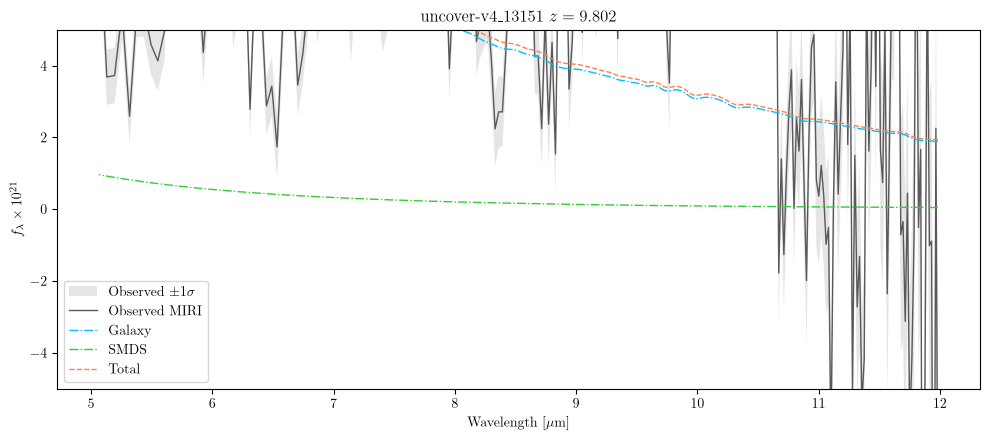

In [10]:
lam = fit_output["lam"]
flux = fit_output["flux"]
err = fit_output["err"]
z = fit_output["z"]
out = fit_output["out"]

fig, ax = plt.subplots(figsize=(10, 4.5))
# Observed spectrum in muted gray; fits in high-contrast colors
ax.fill_between(
    lam, flux - err, flux + err,
    facecolor="0.6", alpha=0.25, edgecolor="none", linewidth=0,
    label=r"Observed $\pm 1\sigma$",
)
ax.plot(lam, flux, lw=1, color="0.35", label="Observed MIRI")
ax.plot(lam, out["galaxy_flux"], lw=1, ls="-.", color="deepskyblue", label="Galaxy")
ax.plot(lam, out["smds_flux"], lw=1, ls="-.", color="limegreen", label="SMDS")
ax.plot(lam, out["total_flux"], lw=1, ls="--", color="coral", label="Total")
# ax.axvline(1.10 * 0.1216 * (1.0 + z), ls="--", color="k", alpha=0.6, label="fit boundary")
# ax.axvline(0.1640 * (1 + z), ls="--", color="c", alpha=0.6, label="He II 1640")
ax.set_xlabel(r"Wavelength [$\mu$m]")
ax.set_ylabel(r"$f_\lambda \times 10^{21}$")
ax.set_title(rf"{fit_output['label']}  $z={z:.3f}$")
# Spectra with coverage blueward of 8 um are usually faint; clip nonphysical red-end spikes
if np.any(lam < 8.0):
    ax.set_ylim(-5.0, 5.0)
ax.legend()
fig.tight_layout()
plt.show()
